/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_35063/656099969.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


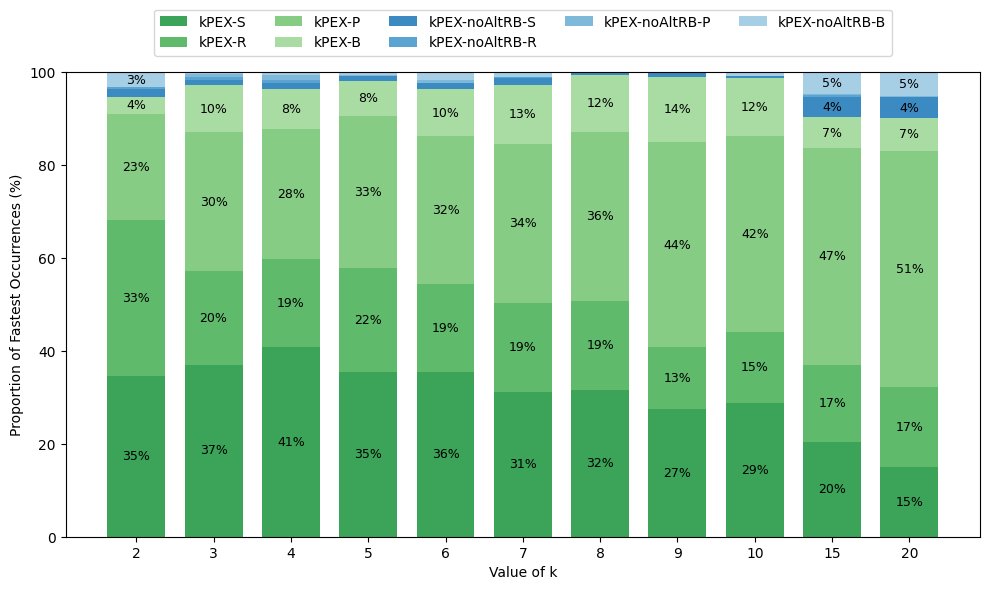

In [19]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# -------------------------------------------------
# Load data
# -------------------------------------------------
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="all")
df = df.rename(columns=lambda c: c.replace("-total", ""))

# -------------------------------------------------
# Define groups (clean, 4 groups)
# -------------------------------------------------
groups = [
    ["kPEX-S","kPEX-R", "kPEX-P", "kPEX-B"],
    ["kPEX-noAltRB-S","kPEX-noAltRB-R", "kPEX-noAltRB-P", "kPEX-noAltRB-B"]
    # ["UMKP-S","UMKP-R", "UMKP-P"],
    # ["UMKP+-S","UMKP+-R", "UMKP+-P"]  
]

all_algos = sum(groups, [])

# -------------------------------------------------
# Preprocess
# -------------------------------------------------
df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)

k_values = [2,3,4,5,6,7,8,9,10,15,20]

# store percentages
results = {algo: [] for algo in all_algos}

# -------------------------------------------------
# Compute winners
# -------------------------------------------------
for k in k_values:

    df_k = df[df["k"] == k]

    if len(df_k) == 0:
        for algo in all_algos:
            results[algo].append(0)
        continue

    winners = df_k[all_algos].idxmin(axis=1)

    win_counts = winners.value_counts()
    total = len(df_k)

    for algo in all_algos:
        wins = win_counts.get(algo, 0)
        percent = (wins / total) * 100
        results[algo].append(percent)

# convert to dataframe
res_df = pd.DataFrame(results, index=k_values)

# -------------------------------------------------
# Colors (one colormap per group)
# -------------------------------------------------
cmaps = [plt.cm.Greens, plt.cm.Blues, plt.cm.Purples, plt.cm.Oranges]

colors = {}
for group, cmap in zip(groups, cmaps):
    shades = cmap(np.linspace(0.65, 0.35, len(group)))
    for algo, shade in zip(group, shades):
        colors[algo] = shade

# -------------------------------------------------
# Stacked bar plot
# -------------------------------------------------
x = np.arange(len(k_values))

fig, ax = plt.subplots(figsize=(10,6))

bottom = np.zeros(len(k_values))

for algo in all_algos:
    vals = res_df[algo].values

    ax.bar(
        x,
        vals,
        bottom=bottom,
        label=algo,
        width=0.75,
        color=colors[algo]
    )

    # annotate
    for i, v in enumerate(vals):
        if v > 3:
            ax.text(
                x[i],
                bottom[i] + v/2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                fontsize=9,
                color="black"
            )

    bottom += vals

# -------------------------------------------------
# Final styling
# -------------------------------------------------
ax.set_xlabel("Value of k")
ax.set_ylabel("Proportion of Fastest Occurrences (%)")

ax.set_xticks(x)
ax.set_xticklabels(k_values)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=5
)

plt.tight_layout()
# plt.show()

In [17]:
cols = ["kPEX-S", "UMKP-S", "UMKP+-S"]

vals = df[cols]

best_algo = vals.idxmin(axis=1)
best_val = vals.min(axis=1)
second_val = vals.apply(lambda row: row.nsmallest(2).iloc[-1], axis=1)

result = df[(second_val >= 2 * best_val)].copy()
result["best_algo"] = best_algo
result["best_val"] = best_val
result["second_best_val"] = second_val
print(result[["dataset", "k"]+cols])


                dataset   k     kPEX-S     UMKP-S    UMKP+-S
1                130bit   8     0.4947     2.5993     1.0020
11               162bit   6     7.0953    29.6227    15.6064
18               176bit   8   136.0658  1800.0000   389.8854
22               208bit   8   198.3983  1800.0000   436.9905
40      3Dspectralwave2  15   281.8319  1800.0000  1181.2078
...                 ...  ..        ...        ...        ...
4207   wikipedia-growth   2    85.2997   662.8238   614.2994
4214  wikipedia_link_de  20     2.4995   494.2531     7.5544
4290      wikisigned-k2  15     9.5842   565.6843    19.6195
4292          wiki-Talk   2    21.4454    84.8292    81.5858
4296          wiki-Talk   6  1800.0000   718.1790   257.2576

[365 rows x 5 columns]
